In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
raw = pd.read_csv('insurance.csv')
df = raw.copy()
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# EDA

In [3]:
df.shape

(1338, 7)

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df.drop_duplicates(inplace=True)

# Statistical Profiling

In [9]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [10]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

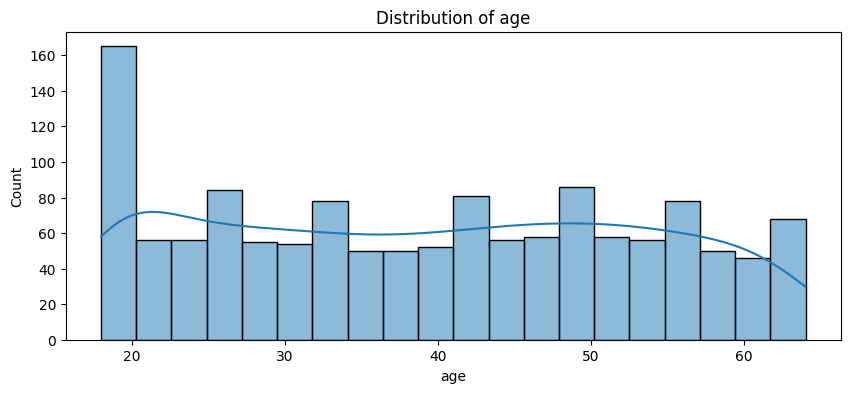

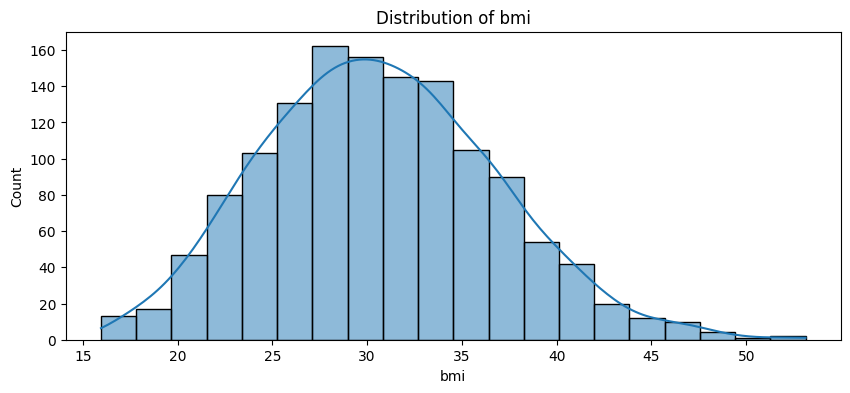

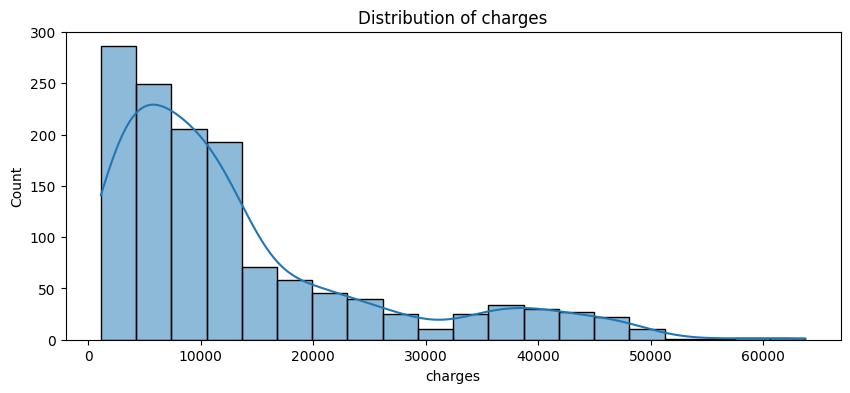

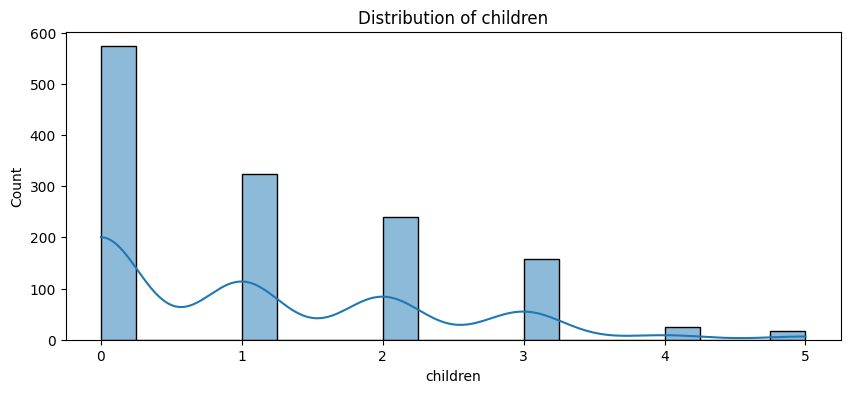

In [11]:
from matplotlib.figure import SubFigure
num_cols = ['age', 'bmi', 'charges', 'children']

for col in num_cols:
    plt.figure(figsize=(10, 4))
    sns.histplot(data=df, x=col, kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.show()

<Axes: xlabel='children', ylabel='count'>

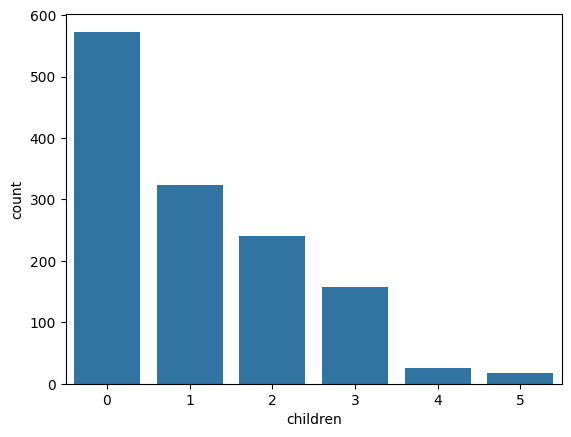

In [12]:
sns.countplot(data=df, x='children')

<Axes: xlabel='sex', ylabel='count'>

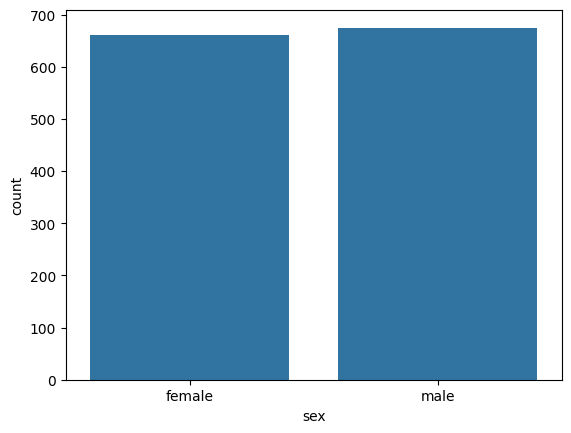

In [13]:
sns.countplot(x = df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

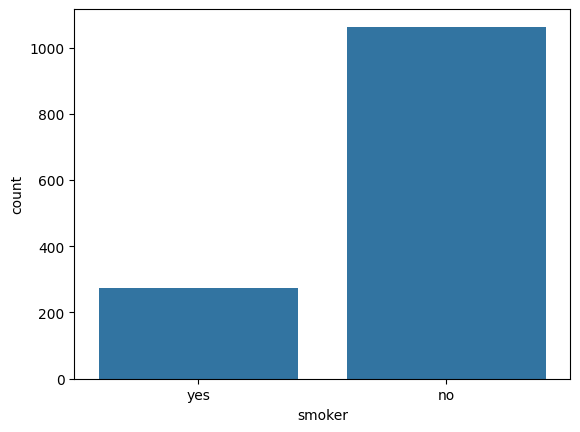

In [14]:
sns.countplot(x = df['smoker'])

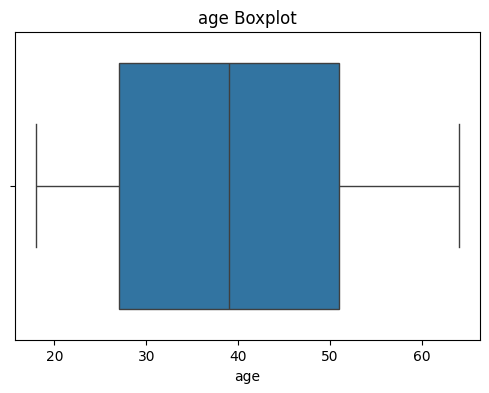

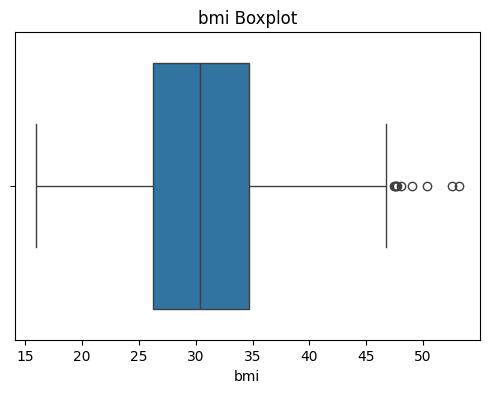

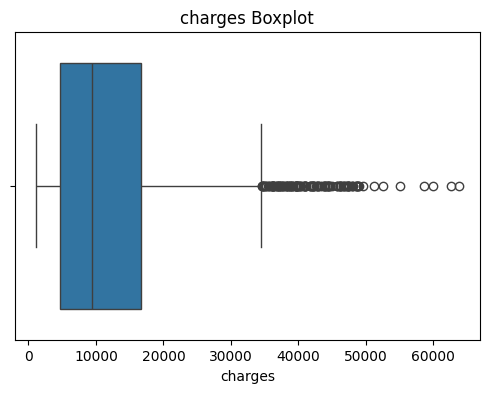

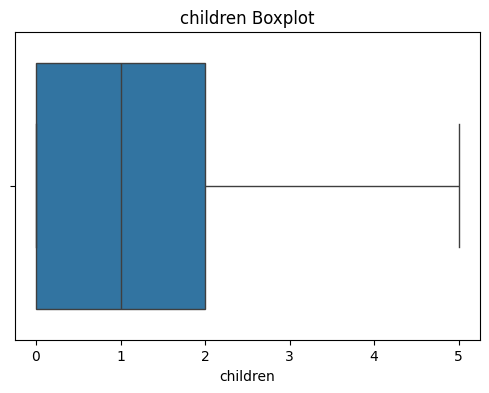

In [17]:
for col in num_cols:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])
  plt.title(col + " Boxplot")
  plt.show()

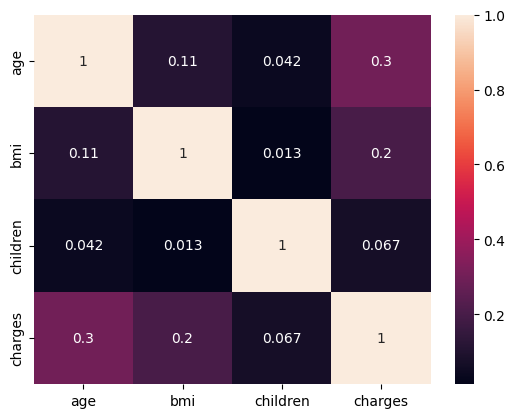

In [18]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

#Data Cleaning and preprocessing

In [20]:
df.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [21]:
df['sex'].value_counts()

,count
sex,
male,675
female,662


In [22]:
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [23]:
df['smoker'].value_counts()

,count
smoker,
no,1063
yes,274


In [24]:
df['smoker'] = df['smoker'].map({'yes': 1, 'no': 0})
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [26]:
df.rename(
    columns={
        'sex' : 'is_female',
        'smoker' : 'is_smoker'
    },
    inplace=True
)

df.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [27]:
df['region'].value_counts()

,count
region,
southeast,364
southwest,325
northwest,324
northeast,324


In [28]:
df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)
df.sample(5)

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
658,48,1,35.91,1,0,26392.26029,0,0,0
790,39,1,41.80,0,0,5662.22500,0,1,0
416,52,0,34.10,0,0,9140.95100,0,1,0
492,18,1,25.08,0,0,2196.47320,0,0,0
587,34,1,30.21,1,1,43943.87610,1,0,0


In [29]:
df = df.astype(int)
df.dtypes

,0
age,int64
is_female,int64
bmi,int64
children,int64
is_smoker,int64
charges,int64
region_northwest,int64
region_southeast,int64
region_southwest,int64


# Feature Engineering and Extraction

<Axes: xlabel='bmi', ylabel='Count'>

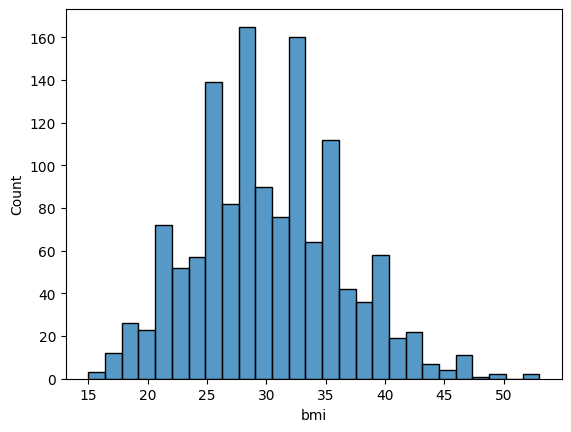

In [30]:
sns.histplot(df['bmi'])

In [31]:
df['bmi_category'] = pd.cut(
    df['bmi'],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'],
    right=False
)

df.sample(5)

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
155,44,0,39,0,0,6948,1,0,0,Obese
1328,23,1,24,2,0,22395,0,0,0,Normal
199,64,1,39,0,0,14901,0,0,0,Obese
526,19,1,30,2,0,24059,1,0,0,Obese
1134,28,0,33,0,0,19673,1,0,0,Obese


In [32]:
df = pd.get_dummies(df, columns=['bmi_category'], prefix='bmi', drop_first=True, dtype=int)
df.sample(5)

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_Normal,bmi_Overweight,bmi_Obese
878,41,0,28,1,0,6282,0,0,1,0,1,0
220,34,1,33,1,0,5012,0,0,1,0,0,1
767,42,1,29,1,0,7050,0,0,1,0,1,0
662,32,1,31,1,0,5148,0,0,0,0,0,1
481,49,0,37,2,0,9304,0,1,0,0,0,1


In [33]:
df = df.astype(int)

In [34]:
df.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_Normal', 'bmi_Overweight', 'bmi_Obese'],
      dtype='object')

In [35]:
from sklearn.preprocessing import StandardScaler

cols= ['age','bmi','children']
scaler = StandardScaler()

df[cols] = scaler.fit_transform(df[cols])
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_Normal,bmi_Overweight,bmi_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


In [39]:
df.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_Normal', 'bmi_Overweight', 'bmi_Obese'],
      dtype='object')

In [40]:
from scipy.stats import pearsonr

# ----------------------------------
# Pearson Correlation Calculation
# ----------------------------------

# List of features to check against target
selected_features = [
    'age', 'bmi', 'children', 'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_Normal', 'bmi_Overweight', 'bmi_Obese'
]

correlations = {
    feature: pearsonr(df[feature], df['charges'])[0]
    for feature in selected_features
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_Obese,0.200348
1,bmi,0.196236
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058046
8,bmi_Normal,-0.104042


In [44]:
cat_features = [
    'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_Normal', 'bmi_Overweight', 'bmi_Obese'
]

In [45]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

df['charges_bin'] = pd.qcut(df['charges'], q=4, labels=False)
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df[col], df['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi_Obese,8.515711,0.036473,Reject Null (Keep Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_Overweight,4.25149,0.235557,Accept Null (Drop Feature)
bmi_Normal,3.708088,0.29476,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


In [48]:
final_df = df[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges','region_southeast','bmi_Obese']]

In [49]:
final_df.sample(5)

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_Obese
1188,0.269096,1,-0.844753,-0.079442,1,21771,0,0
1314,-0.656891,1,-1.171557,1.580143,1,18765,0,0
531,1.622461,1,0.135659,-0.909234,0,14043,0,1
895,1.551231,1,2.259886,-0.909234,0,13063,0,1
1165,-0.300742,1,-0.681351,-0.909234,0,5227,0,0
